# Neural network: selected model

Run the cells from top to bottom, starting in `24_10_2026_TianFeng`.
The `../` paths read the existing shared data. This notebook contains the
complete selected model, trains it from scratch and evaluates its predictions.
It does not import another model script or load a saved checkpoint.

The selected input combines the **previous, current and next windows**.
This is an **offline model**, or a prediction delayed until the following
window is available. Context never crosses participants. Rows are assumed
chronological; within-participant recording boundaries are not supplied.

The flow is: **read data → build three-window input → scale → train the MLP
→ predict → apply posture memory → evaluate**. The selected settings and
how they were chosen are explained below. Running this notebook does not
repeat the tuning study or write any files.


## 1. Imports

NumPy handles the data; scikit-learn supplies scaling and metrics;
PyTorch trains the network; Matplotlib displays the plots. The thread and
seed settings help reproduce the existing training run on this environment.


In [1]:
import os
from pathlib import Path

for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
    os.environ.setdefault(name, '2')

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_recall_fscore_support
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.set_num_threads(2)
np.set_printoptions(precision=4, suppress=True)


## 2. Selected settings

We keep the hidden layers 256–128–64, ReLU, dropout 0.3/0.3/0.2, Adam
learning rate 0.001, weight decay 0.0001 and batch size 128.

The changes are three-window features, all training rows, no PCA and
class weights proportional to `1 / sqrt(class count)`. The selected duration
is **15 epochs**, the median best epoch across nine validation folds.
Validation stopping monitored transition macro-F1 with patience 12.
The final fit uses that fixed duration; it does not early-stop on test labels.

Across those nine matched folds, NN + memory transition F1 rose from
**0.7835 to 0.9084**, and common-class F1 rose from **0.9162 to 0.9214**.
Random oversampling to 100 reached 0.9080 transition F1, so it was not retained.
The shortlist and final setting were chosen without reading test labels.

The selection study first compared 19 configurations on three participant-disjoint
folds. It varied context, PCA, class weighting, sampling and the stopping
criterion. Six shortlisted settings were repeated with two additional
split/training seed schedules, for 93 fits in total. All preprocessing was
fitted inside each training fold; validation rows were never resampled.
The original reference stopped on all-class macro-F1. New candidates stopped
on the six-transition macro-F1, with at most 100 epochs and patience 12.
The final 15 epochs are the median of the selected setting's nine best epochs.


In [2]:
data = Path('../smartphone+based+recognition+of+human+activities+and+postural+transitions')

SEED = 42
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
WEIGHT_POWER = 0.5
BATCH_SIZE = 128
EPOCHS = 15
memory = {'steps': 8, 'alpha': 1.0, 'minimum_static_mass': 0.75}


## 3. Read the training data

The shared training CSV starts with `subject_id`, `activity_id` and
`activity_label`. Skip its header and select columns 3–563 (zero-based) to
read only the 561 sensor features. Excluding the metadata prevents activity
labels and participant IDs from entering the NN inputs.

The activity and participant text files in the shared dataset use the same
row order. Subtracting 1 changes activity labels 1–12 into output indices 0–11.


In [3]:
X = np.loadtxt('../Minh/hapt_train.csv', delimiter=',',
               skiprows=1, usecols=range(3, 564), dtype=np.float32)
y = np.loadtxt(data / 'Train/y_train.txt', dtype=int) - 1
subject = np.loadtxt(data / 'Train/subject_id_train.txt', dtype=int)
names = np.loadtxt(data / 'activity_labels.txt', dtype=str)[:, 1].tolist()


print(f'Training data: {len(X)} windows, {X.shape[1]} features, {len(np.unique(subject))} participants')


Training data: 7767 windows, 561 features, 21 participants


## 4. Keep all classes and add neighbouring windows

The table shows the original imbalance. We keep all 7,767 training windows:
validation favoured retaining the common-class information rather than
randomly capping those classes at 300. Weighted loss still increases the
importance of rare-class examples.

For each row we concatenate its previous, current and following 561-feature
vectors, producing 1,683 inputs. At a participant boundary, replace a missing
neighbour with the current row. Build this context before any training shuffle.
The loop checks boundaries using participant IDs, never activity labels.


In [4]:
counts = np.bincount(y, minlength=12)
print(f'{"Activity":22} {"Training windows":>16}')
for activity, name in enumerate(names):
    print(f'{name:22} {counts[activity]:16d}')

previous = np.vstack([X[:1], X[:-1]])
following = np.vstack([X[1:], X[-1:]])
for row in range(len(X)):
    if row == 0 or subject[row] != subject[row - 1]:
        previous[row] = X[row]
    if row == len(X) - 1 or subject[row] != subject[row + 1]:
        following[row] = X[row]
X_context = np.hstack([previous, X, following])
print('Context input shape:', X_context.shape)


Activity               Training windows
WALKING                            1226
WALKING_UPSTAIRS                   1073
WALKING_DOWNSTAIRS                  987
SITTING                            1293
STANDING                           1423
LAYING                             1413
STAND_TO_SIT                         47
SIT_TO_STAND                         23
SIT_TO_LIE                           75
LIE_TO_SIT                           60
STAND_TO_LIE                         90
LIE_TO_STAND                         57
Context input shape: (7767, 1683)


## 5. Scale using training data only

The scaler learns a mean and scale for every contextual feature using
training rows only. We retain the full feature vector: PCA was compared
during validation but was not part of the selected setting. Keep `scaler`
for the test transformation, which must use `transform`, not a new fit.


In [5]:
scaler = StandardScaler()
train_x = scaler.fit_transform(X_context).astype(np.float32)
train_y = y


## 6. Build the NN, class weights and optimiser

The MLP is **1,683 → 256 → 128 → 64 → 12**. The output is 12 logits;
cross-entropy applies the required log-softmax internally.

Weights are `(training rows / (12 × class count)) ** 0.5`. The common
constant cancels in the weighted-mean loss, so relative weights are
`1 / sqrt(class count)`. This is milder than inverse-frequency weighting.
Adam and the shuffled training batches work as in the previous NN.


In [6]:
torch.manual_seed(SEED)
model = nn.Sequential(
    nn.Linear(train_x.shape[1], 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(64, 12),
)
for layer in model:
    if isinstance(layer, nn.Linear):
        if layer.out_features == 12:
            nn.init.xavier_uniform_(layer.weight)
        else:
            nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
        nn.init.zeros_(layer.bias)

counts = np.bincount(train_y, minlength=12)
weights = torch.tensor((len(train_y) / (12 * counts)) ** WEIGHT_POWER, dtype=torch.float32)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
loader = DataLoader(TensorDataset(torch.from_numpy(train_x), torch.from_numpy(train_y)),
                    batch_size=BATCH_SIZE, shuffle=True,
                    generator=torch.Generator().manual_seed(SEED))


## 7. Train for 15 epochs

The outer loop runs over epochs; the inner loop visits all training batches.
For each batch: clear old gradients, predict logits, calculate weighted
cross-entropy, backpropagate, then update weights. Dividing by the sum of
class weights gives the weighted mean loss used by the current model.

After each epoch, `eval()` switches off dropout and uses stored batch-normalisation
statistics. `no_grad()` measures whole-training-set loss without tracking gradients.
We print progress at the first epoch, every fifth epoch and the final epoch.


In [7]:
train_losses = []
batch_losses = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    for batch_x, batch_y in loader:
        optimizer.zero_grad()
        logits = model(batch_x)
        losses = F.cross_entropy(logits, batch_y, reduction='none')
        loss = (losses * weights[batch_y]).sum() / weights[batch_y].sum()
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        target = torch.from_numpy(train_y)
        logits = model(torch.from_numpy(train_x))
        losses = F.cross_entropy(logits, target, reduction='none')
        train_loss = (losses * weights[target]).sum() / weights[target].sum()
    train_losses.append(train_loss.item())
    if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
        print(f'Epoch {epoch:2d}/{EPOCHS}: training loss {train_loss.item():.4f}')


Epoch  1/15: training loss 0.3762
Epoch  5/15: training loss 0.0570
Epoch 10/15: training loss 0.0358
Epoch 15/15: training loss 0.0223


## 8. Plot training loss

The left plot shows whole-training-set loss with dropout off after each
epoch. The right shows individual training-batch losses, which jump as the
batch contents and dropout change. These curves describe optimisation;
they cannot establish generalisation by themselves. In the earlier
participant-validation study, training loss kept falling while validation
loss eventually rose. Selecting the best transition-F1 checkpoint limited
later deterioration; it did not prove that all overfitting was eliminated.


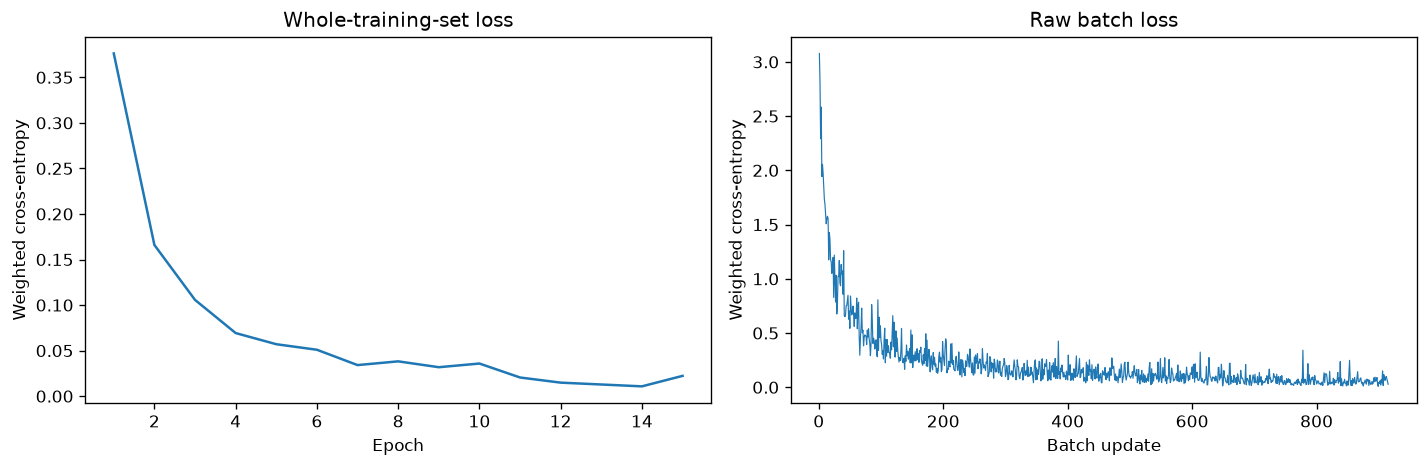

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, EPOCHS + 1), train_losses)
axes[0].set(title='Whole-training-set loss', xlabel='Epoch', ylabel='Weighted cross-entropy')
axes[1].plot(range(1, len(batch_losses) + 1), batch_losses, linewidth=0.7)
axes[1].set(title='Raw batch loss', xlabel='Batch update', ylabel='Weighted cross-entropy')
fig.tight_layout()
plt.show()


## 9. Build test context and predict

Apply the same neighbour construction to the ordered test features, then
use the training scaler's `transform`. No test activity labels are loaded
at this point. Each NN prediction uses the current and next windows, so
this evaluation is offline rather than an immediate online prediction.

Softmax supplies scores for the memory rule; these scores are not calibrated
confidence estimates. `baseline` holds the contextual NN predictions before memory.


In [9]:
X_test = np.loadtxt(data / 'Test/X_test.txt', dtype=np.float32)
test_subject = np.loadtxt(data / 'Test/subject_id_test.txt', dtype=int)

previous = np.vstack([X_test[:1], X_test[:-1]])
following = np.vstack([X_test[1:], X_test[-1:]])
for row in range(len(X_test)):
    if row == 0 or test_subject[row] != test_subject[row - 1]:
        previous[row] = X_test[row]
    if row == len(X_test) - 1 or test_subject[row] != test_subject[row + 1]:
        following[row] = X_test[row]
test_context = np.hstack([previous, X_test, following])
test_x = scaler.transform(test_context).astype(np.float32)

model.eval()
with torch.no_grad():
    probabilities = model(torch.from_numpy(test_x)).softmax(dim=1).numpy()
baseline = probabilities.argmax(axis=1)


## 10. Apply the selected posture-memory rule

When the NN predicts sit-to-lie (index 8) or stand-to-lie (index 10), look
at up to eight **earlier** windows from that participant. Sum their sitting
and standing scores (indices 3 and 4). With combined score mass at least
0.75, the fraction coming from standing determines the starting posture:
above 0.5 chooses stand-to-lie; otherwise sit-to-lie. Insufficient evidence
keeps the original conditional score. Alpha 1 gives the past score full weight.

Only those two output labels can change. This is postprocessing, not a
new NN input or trainable layer. It uses earlier NN scores, never true labels,
and history resets at a participant boundary. The scores are uncalibrated;
0.75 is a sum across history, not a 75% confidence guarantee.

The method assumes contiguous, chronological rows. A separate recording
from the same person needs a separate sequence ID to reset the history.

The rule uses earlier contextual NN scores. The overall model still needs
the next input window because the NN itself uses three-window context.


In [10]:
predictions = baseline.copy()
gate = np.isin(baseline, [8, 10])
pair_mass = probabilities[:, [8, 10]].sum(axis=1)
current_score = np.divide(probabilities[:, 10], pair_mass,
                          out=np.full(len(X_test), 0.5), where=pair_mass > 0)
past_score = current_score.copy()
evidence = np.zeros(len(X_test))
start = 0

for row in range(len(X_test)):
    if row == 0 or test_subject[row] != test_subject[row - 1]:
        start = row
    first = max(start, row - memory['steps'])
    previous = probabilities[first:row, [3, 4]].sum(axis=0)
    evidence[row] = previous.sum()
    if evidence[row] >= memory['minimum_static_mass']:
        past_score[row] = previous[1] / evidence[row]

score = (1 - memory['alpha']) * current_score + memory['alpha'] * past_score
predictions[gate] = np.where(score[gate] > 0.5, 10, 8)
changed = np.flatnonzero(predictions != baseline)

print(f'Posture memory changed {len(changed)} predictions.')


Posture memory changed 14 predictions.


## 11. Evaluate the predictions

Now load test labels to compare the plain NN with NN + memory. Accuracy
counts all correct windows; macro-F1 gives each of the 12 classes equal
weight. Transition F1 averages only the last six classes.

The class table gives precision, recall, F1 and correct/support. **Class
accuracy means recall**, shown as a percentage; it is not a separate metric.
Small class supports mean a few windows can substantially change the scores.


In [11]:
y_test = np.loadtxt(data / 'Test/y_test.txt', dtype=int) - 1

print(f'{"Method":23} {"Accuracy":>10} {"Macro-F1":>10} {"Transition F1":>15}')
for title, labels in [('Context MLP', baseline), ('Context MLP + memory', predictions)]:
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, labels, labels=range(12), zero_division=0)
    print(f'{title:23} {100 * np.mean(y_test == labels):9.4f}%'
          f' {f1.mean():10.6f} {f1[6:].mean():15.6f}')

print('\nContext MLP + posture memory: all 12 classes')
print(f'{"Activity":22} {"Precision":>9} {"Recall":>9} {"F1":>9}'
      f' {"Class acc %":>12} {"Correct/N":>11}')
for activity, name in enumerate(names):
    correct = np.sum((y_test == activity) & (predictions == activity))
    recognized = f'{correct}/{support[activity]}'
    print(f'{name:22} {precision[activity]:9.4f} {recall[activity]:9.4f}'
          f' {f1[activity]:9.4f} {100 * recall[activity]:12.2f} {recognized:>11}')


Method                    Accuracy   Macro-F1   Transition F1
Context MLP               95.4775%   0.926768        0.893450
Context MLP + memory      95.8571%   0.952720        0.945353

Context MLP + posture memory: all 12 classes
Activity               Precision    Recall        F1  Class acc %   Correct/N
WALKING                   0.9666    0.9919    0.9791        99.19     492/496
WALKING_UPSTAIRS          0.9603    0.9745    0.9673        97.45     459/471
WALKING_DOWNSTAIRS        0.9876    0.9452    0.9659        94.52     397/420
SITTING                   0.9385    0.9311    0.9348        93.11     473/508
STANDING                  0.9146    0.9442    0.9292        94.42     525/556
LAYING                    1.0000    0.9688    0.9842        96.88     528/545
STAND_TO_SIT              0.9565    0.9565    0.9565        95.65       22/23
SIT_TO_STAND              1.0000    1.0000    1.0000       100.00       10/10
SIT_TO_LIE                0.9688    0.9688    0.9688        96.88 

## 12. Display the confusion matrix

Rows are actual activities and columns are predictions. The diagonal counts
correct predictions; off-diagonal counts show the remaining confusions.
Overall accuracy and macro-F1 appear in the title.

Posture memory only swaps sit-to-lie and stand-to-lie. It cannot recover
either class if the original NN predicted outside that pair, and it leaves
the other ten classes' metrics unchanged, including lie-to-sit.


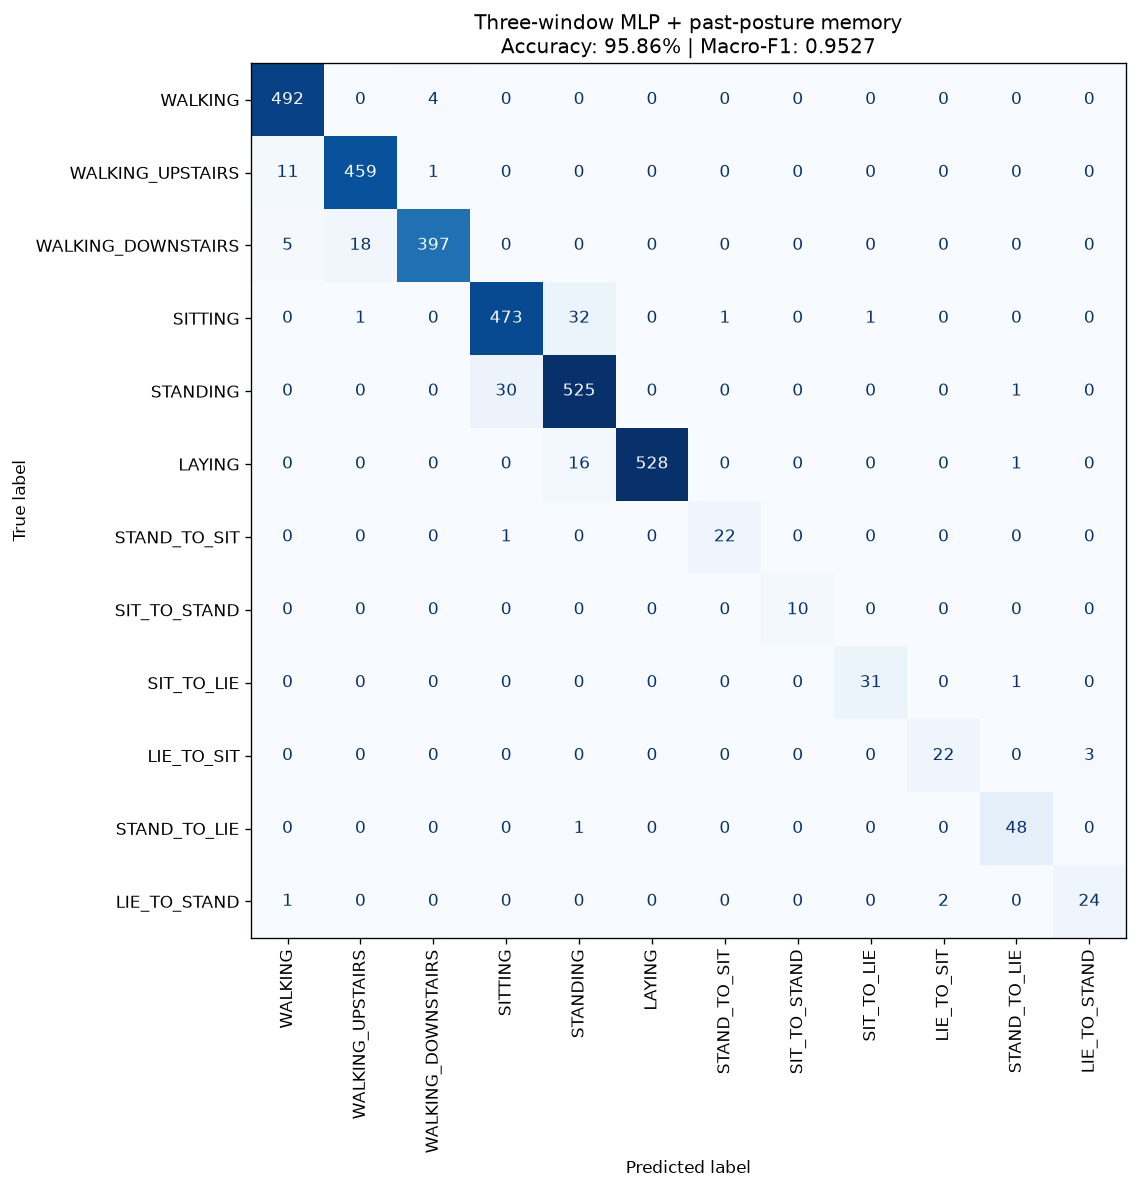

In [12]:
matrix = confusion_matrix(y_test, predictions, labels=range(12))
accuracy = np.mean(y_test == predictions)
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(matrix, display_labels=names).plot(
    ax=ax, cmap='Blues', values_format='d', xticks_rotation=90, colorbar=False)
ax.set_title(f'Three-window MLP + past-posture memory\nAccuracy: {100 * accuracy:.2f}% | Macro-F1: {f1.mean():.4f}')
fig.tight_layout()
plt.show()


The trained model and scaler remain in memory; no files are written.

The setting was frozen using training-participant validation before test
evaluation. The project's test set was inspected earlier, so its results
remain developmental rather than an untouched final estimate. Context
assumes chronological rows and resets only at participant boundaries.
